In [5]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [6]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
x_train = x_train.astype("float32")/255.0
x_test = x_test.astype("float32")/255.0
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)
class_names = ["T-shirt/top","Trouser","Pullover","Dress","Coat",
"Sandal","Shirt","Sneaker","Bag","Ankle boot"]
print("Train shape:", x_train.shape, "Test shape:", x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train shape: (60000, 28, 28, 1) Test shape: (10000, 28, 28, 1)


In [7]:
model = keras.Sequential([
layers.Conv2D(32, (3,3), activation="relu", input_shape=(28,28,1)),
layers.MaxPooling2D((2,2)),
layers.Conv2D(64, (3,3), activation="relu"),
layers.MaxPooling2D((2,2)),
layers.Flatten(),
layers.Dense(64, activation="relu"),
layers.Dense(10, activation="softmax")

])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()
history = model.fit(x_train, y_train, epochs=3, batch_size=128, validation_split=0.1, verbose=2)

c:\Users\sakef\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
422/422 - 11s - 26ms/step - accuracy: 0.7811 - loss: 0.6003 - val_accuracy: 0.8458 - val_loss: 0.4224
Epoch 2/3
422/422 - 9s - 21ms/step - accuracy: 0.8634 - loss: 0.3849 - val_accuracy: 0.8690 - val_loss: 0.3627
Epoch 3/3
422/422 - 9s - 20ms/step - accuracy: 0.8795 - loss: 0.3368 - val_accuracy: 0.8785 - val_loss: 0.3306


Test accuracy: 0.8748999834060669


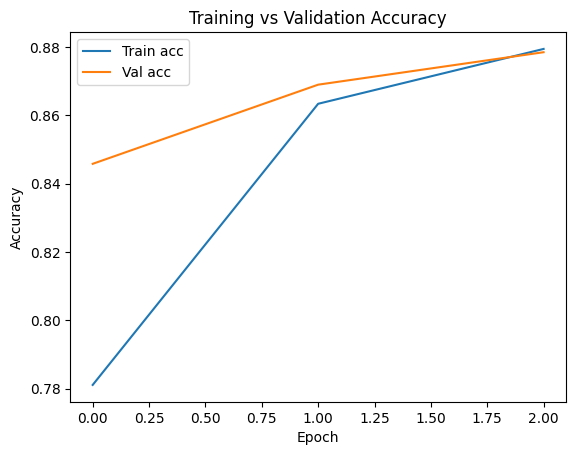

In [8]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", test_acc)
plt.plot(history.history["accuracy"], label="Train acc")
plt.plot(history.history["val_accuracy"], label="Val acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

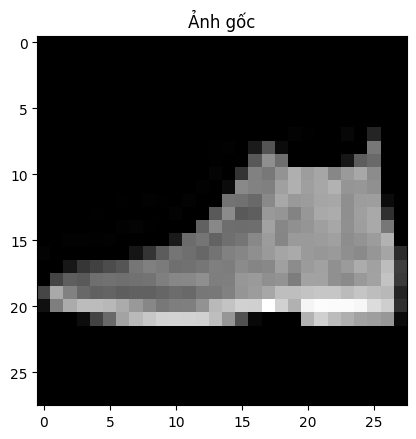

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step


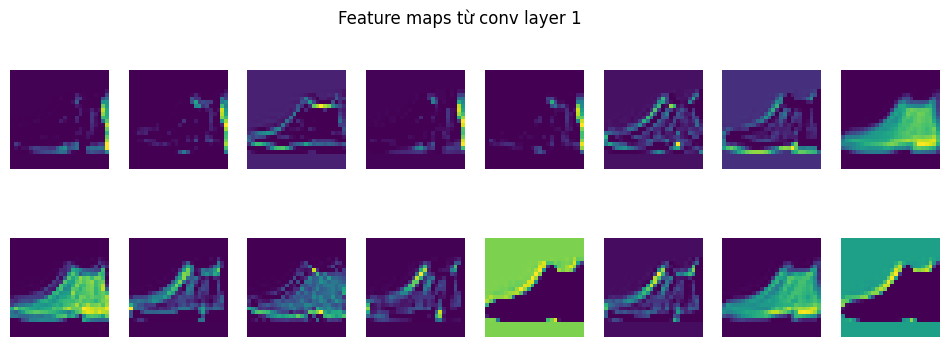

In [10]:
sample_img = x_test[0:1]
plt.imshow(sample_img[0,:,:,0], cmap="gray")
plt.title("Ảnh gốc")
plt.show()
model.predict(sample_img)
layer_outputs = [layer.output for layer in model.layers if "conv" in layer.name]
activation_model = keras.models.Model(inputs=model.inputs, outputs=layer_outputs)
activations = activation_model.predict(sample_img)
first_layer_activation = activations[0]
fig, axes = plt.subplots(2, 8, figsize=(12,4))
for i, ax in enumerate(axes.flat):
    ax.imshow(first_layer_activation[0,:,:,i], cmap="viridis")
    ax.axis("off")
plt.suptitle("Feature maps từ conv layer 1")
plt.show()